# Fine-Tuning idT5 + LoRA: *Two-Step Fine-Tuning*

**Model dasar** : `muchad/idt5-base`  
**Teknik** : Low-Rank Adaptation (LoRA)  
**Task** : Peringkasan Berita  
**Dataset** : Liputan6 dan Berita BPS Provinsi DKI Jakarta  

## 1. Instalasi Library

In [ ]:
!pip install transformers datasets peft accelerate scikit-learn pandas openpyxl evaluate rouge_score sentencepiece -q
!pip install torchao --upgrade -q

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 32.1 MB/s eta 0:00:00


## 2. Import Library

In [ ]:
import os
import re
import numpy as np
import pandas as pd
import torch
import evaluate

from datasets import load_dataset, Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments,
    DataCollatorForSeq2Seq,
    EarlyStoppingCallback,
)
from peft import (
    LoraConfig,
    TaskType,
    get_peft_model,
    PeftModel,
)

# Cek GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

Device: cuda
GPU: Tesla T4
VRAM: 15.6 GB


## 3. Konfigurasi Global

In [ ]:
# model
MODEL_NAME        = 'muchad/idt5-base'

# panjang token
MAX_INPUT_LENGTH  = 512   # artikel input
MAX_TARGET_LENGTH = 128   # ringkasan output

# jumlah data Liputan6
N_LIPUTAN6_TRAIN  = 193883
N_LIPUTAN6_VAL    = 10972
N_LIPUTAN6_TEST   = 10972

# output
STEP1_OUTPUT_DIR  = './idt5-lora-step1-liputan6'
STEP1_MERGED_DIR  = './idt5-merged-step1-liputan6'
STEP2_OUTPUT_DIR  = './idt5-lora-step2-bps'
STEP2_MERGED_DIR  = './idt5-merged-step2-bps'

print('Konfigurasi global berhasil dimuat.')

Konfigurasi global berhasil dimuat.


## 4. Load Tokenizer

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print('Tokenizer loaded:', MODEL_NAME)

config.json:   0%|          | 0.00/742 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/756k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/65.0 [00:00<?, ?B/s]

Tokenizer loaded: muchad/idt5-base


## 5. Fungsi Preprocessing & Tokenisasi

In [ ]:
def clean_text(text):
    """Membersihkan teks."""
    # handle format Liputan6 (list of list of tokens)
    if isinstance(text, list) and len(text) > 0 and isinstance(text[0], list):
        text = ' '.join([' '.join(sent) for sent in text])
    elif isinstance(text, list):
        text = ' '.join(text)

    # hapus kata Liputan6,com di awal kalimat
    text = re.sub(r'^liputan6\s*[\.,]\s*com\s*,\s*[a-zA-Z\s]+\s*[:\-]\s*', '', text, flags=re.IGNORECASE)

    # hapus author tags
    text = re.sub(r'\s*\([^)]+\)\s*\.?\s*$', '', text)
    text = re.sub(r'\s*\([^)]+/[^)]+\)\s*', ' ', text)
    text = re.sub(r'\s*\([^)]*(liputan\s*6|sctv|idn\s*times|antara|foto)[^)]*\)\s*', ' ', text, flags=re.IGNORECASE)

    # hapus keterangan gambar/tabel
    text = re.sub(r'^Ilustrasi[^)]+\)\s*', '', text, flags=re.IGNORECASE)

    text = text.lower()

    if not isinstance(text, str):
        return ''

    text = re.sub(r'&#[0-9]+;', ' ', text)
    text = re.sub(r'&[a-zA-Z]+;', ' ', text)
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    text = re.sub(r'[^\w\s.,!?;:\-\'\"()%]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()

    return text


def tokenize_fn(examples, input_col, target_col):
    inputs  = ['summarize: ' + clean_text(t) for t in examples[input_col]]
    targets = [clean_text(t) for t in examples[target_col]]

    model_inputs = tokenizer(
        inputs,
        max_length=MAX_INPUT_LENGTH,
        truncation=True,
        padding=False,
    )

    labels = tokenizer(
        text_target=targets,
        max_length=MAX_TARGET_LENGTH,
        truncation=True,
        padding=False,
    )

    model_inputs['labels'] = labels['input_ids']
    return model_inputs

print('Fungsi preprocessing & tokenisasi siap.')

Fungsi preprocessing & tokenisasi siap.


## 6. Metrik Evaluasi ROUGE

In [ ]:
rouge = evaluate.load('rouge')
bleu  = evaluate.load('bleu')

def compute_metrics(eval_pred):
    predictions, labels = eval_pred

    predictions = np.clip(predictions, 0, tokenizer.vocab_size - 1)
    decoded_preds = tokenizer.batch_decode(predictions, skip_special_tokens=True)

    # ganti -100 pada labels dengan pad_token_id sebelum decode
    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)

    decoded_preds  = [pred.strip() for pred in decoded_preds]
    decoded_labels = [label.strip() for label in decoded_labels]

    # hitung ROUGE
    result_rouge = rouge.compute(
        predictions=decoded_preds,
        references=decoded_labels,
        use_stemmer=False,
    )

    # hitung BLEU
    result_bleu = bleu.compute(
        predictions=decoded_preds,
        references=[[label] for label in decoded_labels],
    )

    return {
        'rouge1' : round(result_rouge['rouge1'], 4),
        'rouge2' : round(result_rouge['rouge2'], 4),
        'rougeL' : round(result_rouge['rougeL'], 4),
        'bleu'   : round(result_bleu['bleu'], 4),
    }

print('compute_metrics siap.')

compute_metrics siap.


## 7. Konfigurasi LoRA

In [ ]:
# Konfigurasi LoRA untuk T5
lora_config = LoraConfig(
    task_type=TaskType.SEQ_2_SEQ_LM,    # sequence-to-sequence
    r=16,                               # rank LoRA
    lora_alpha=32,                      # alpha
    target_modules=['q', 'v'],          # layer attention T5
    lora_dropout=0.1,                   # dropout untuk regularisasi
    bias='none',                        # tidak melatih bias
    inference_mode=False,               # bukan mode inferensi
)

print('Konfigurasi LoRA siap.')
print(f'  rank (r)       : {lora_config.r}')
print(f'  lora_alpha     : {lora_config.lora_alpha}')
print(f'  target_modules : {lora_config.target_modules}')

Konfigurasi LoRA siap.
  rank (r)       : 16
  lora_alpha     : 32
  target_modules : {'q', 'v'}


---
# STEP 1 — Fine-Tuning dengan Dataset Liputan6

## 8. Load & Persiapan Dataset Liputan6

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import json
import zipfile
from pathlib import Path
from datasets import load_dataset

DRIVE_DIR  = '/content/drive/MyDrive/Semester 8/04 Checkpoint 3 - Setelah Sempro/Dataset/liputan6_data'
LOCAL_DIR  = '/content/liputan6'

zips = {
    f'{DRIVE_DIR}/canonical/canonical_train.zip' : f'{LOCAL_DIR}/canonical/train',
    f'{DRIVE_DIR}/canonical/canonical_dev.zip'   : f'{LOCAL_DIR}/canonical/dev',
    f'{DRIVE_DIR}/canonical/canonical_test.zip'  : f'{LOCAL_DIR}/canonical/test',
    f'{DRIVE_DIR}/xtreme/xtreme_dev.zip'         : f'{LOCAL_DIR}/xtreme/dev',
    f'{DRIVE_DIR}/xtreme/xtreme_test.zip'        : f'{LOCAL_DIR}/xtreme/test',
}

print('=== Extract ZIP ===\n')
for zip_path, extract_dir in zips.items():
    zip_name = os.path.basename(zip_path)
    if not os.path.exists(zip_path):
        print(f'✗ {zip_name} — tidak ditemukan, skip.')
        continue
    os.makedirs(extract_dir, exist_ok=True)
    print(f'Mengextract {zip_name}...')
    with zipfile.ZipFile(zip_path, 'r') as z:
        z.extractall(extract_dir)
    actual = len([f for f in os.listdir(extract_dir) if f.endswith('.json')])
    print(f'  ✓ {actual:,} file terekstrak ke {extract_dir}\n')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
=== Extract ZIP ===

Mengextract canonical_train.zip...
  ✓ 193,883 file terekstrak ke /content/liputan6/canonical/train

Mengextract canonical_dev.zip...
  ✓ 10,972 file terekstrak ke /content/liputan6/canonical/dev

Mengextract canonical_test.zip...
  ✓ 10,972 file terekstrak ke /content/liputan6/canonical/test

Mengextract xtreme_dev.zip...
  ✓ 4,948 file terekstrak ke /content/liputan6/xtreme/dev

Mengextract xtreme_test.zip...
  ✓ 3,862 file terekstrak ke /content/liputan6/xtreme/test



In [ ]:
splits_expected = {
    'canonical/train': 193883,
    'canonical/dev'  : 10972,
    'canonical/test' : 10972,
    'xtreme/dev'     : 4948,
    'xtreme/test'    : 3862,
}

print('=== Merge JSON → JSONL ===\n')
for split, expected in splits_expected.items():
    folder      = f'{LOCAL_DIR}/{split}'
    output_path = f'{LOCAL_DIR}/{split}.jsonl'

    if not os.path.exists(folder):
        print(f'✗ {split} — folder tidak ditemukan, skip.')
        continue

    files = sorted(Path(folder).glob('*.json'))
    print(f'Menggabungkan {len(files):,} file → {split}.jsonl ...')

    with open(output_path, 'w', encoding='utf-8') as out:
        for f in files:
            with open(f, 'r', encoding='utf-8') as inp:
                data = json.load(inp)
                out.write(json.dumps(data, ensure_ascii=False) + '\n')

    actual = sum(1 for _ in open(output_path, encoding='utf-8'))
    status = '✓' if actual == expected else '✗'
    print(f'  {status} {actual:,} / {expected:,} baris\n')

=== Merge JSON → JSONL ===

Menggabungkan 193,883 file → canonical/train.jsonl ...
  ✓ 193,883 / 193,883 baris

Menggabungkan 10,972 file → canonical/dev.jsonl ...
  ✓ 10,972 / 10,972 baris

Menggabungkan 10,972 file → canonical/test.jsonl ...
  ✓ 10,972 / 10,972 baris

Menggabungkan 4,948 file → xtreme/dev.jsonl ...
  ✓ 4,948 / 4,948 baris

Menggabungkan 3,862 file → xtreme/test.jsonl ...
  ✓ 3,862 / 3,862 baris



In [ ]:
print('=== Load Dataset ===\n')
liputan6_raw = load_dataset(
    'json',
    data_files={
        'train'     : f'{LOCAL_DIR}/canonical/train.jsonl',
        'validation': f'{LOCAL_DIR}/canonical/dev.jsonl',
        'test'      : f'{LOCAL_DIR}/canonical/test.jsonl',
    }
)

print('Struktur dataset:')
print(liputan6_raw)
print('\nKolom:', liputan6_raw['train'].column_names)
print('\nContoh data:')
print(liputan6_raw['train'][0])

=== Load Dataset ===



Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Struktur dataset:
DatasetDict({
    train: Dataset({
        features: ['id', 'url', 'clean_article', 'clean_summary', 'extractive_summary'],
        num_rows: 193883
    })
    validation: Dataset({
        features: ['id', 'url', 'clean_article', 'clean_summary', 'extractive_summary'],
        num_rows: 10972
    })
    test: Dataset({
        features: ['id', 'url', 'clean_article', 'clean_summary', 'extractive_summary'],
        num_rows: 10972
    })
})

Kolom: ['id', 'url', 'clean_article', 'clean_summary', 'extractive_summary']

Contoh data:
{'id': 100000, 'url': 'https://www.liputan6.com/news/read/100000/yudhoyono-berharap-masalah-kemiskinan-menjadi-bahasan-penting', 'clean_article': [['Liputan6', '.', 'com', ',', 'Jakarta', ':', 'Presiden', 'Susilo', 'Bambang', 'Yudhoyono', 'menekankan', 'bahwa', 'tantangan', 'terbesar', 'yang', 'dihadapi', 'bangsa-bangsa', 'Asia', 'dan', 'Afrika', 'saat', 'ini', 'adalah', 'masalah', 'kemiskinan', 'yang', 'sangat', 'buruk', '.'], ['Yudhoyono',

In [ ]:
INPUT_COL_L6  = 'clean_article'
TARGET_COL_L6 = 'clean_summary'

train_l6 = liputan6_raw['train'].shuffle(seed=42).select(range(N_LIPUTAN6_TRAIN))
val_l6   = liputan6_raw['validation'].shuffle(seed=42).select(range(N_LIPUTAN6_VAL))
test_l6 = liputan6_raw['test'].shuffle(seed=42).select(range(N_LIPUTAN6_TEST))

print(f'Train Liputan6 : {len(train_l6)} data')
print(f'Val Liputan6   : {len(val_l6)} data')
print(f'Test Liputan6  : {len(test_l6)} data')

def liputan6_to_str(x):
    """Ubah list of list of tokens → string."""
    if isinstance(x, list) and len(x) > 0 and isinstance(x[0], list):
        return ' '.join([' '.join(sent) for sent in x])
    elif isinstance(x, list):
        return ' '.join(x)
    return x

sample_lens = [len(liputan6_to_str(x).split()) for x in train_l6[INPUT_COL_L6][:500]]
print(f'\nRata-rata panjang artikel   : {np.mean(sample_lens):.0f} kata')
print(f'Rata-rata panjang ringkasan : {np.mean([len(liputan6_to_str(x).split()) for x in train_l6[TARGET_COL_L6][:500]]):.0f} kata')

Train Liputan6 : 193883 data
Val Liputan6   : 10972 data
Test Liputan6  : 10972 data

Rata-rata panjang artikel   : 223 kata
Rata-rata panjang ringkasan : 31 kata


In [ ]:
def tokenize_l6(examples):
    return tokenize_fn(examples, INPUT_COL_L6, TARGET_COL_L6)

cols_to_remove = train_l6.column_names

train_l6_tok = train_l6.map(tokenize_l6, batched=True, remove_columns=cols_to_remove)
val_l6_tok   = val_l6.map(tokenize_l6, batched=True, remove_columns=cols_to_remove)
test_l6_tok  = test_l6.map(tokenize_l6, batched=True, remove_columns=cols_to_remove)

print('Tokenisasi Liputan6 selesai.')
print('Contoh panjang input:', len(train_l6_tok[0]['input_ids']))
print('Contoh panjang label:', len(train_l6_tok[0]['labels']))

print('Contoh hasil tokenisasi (input_ids dan labels untuk contoh pertama):')
print(train_l6_tok[0])

Map:   0%|          | 0/193883 [00:00<?, ? examples/s]

Map:   0%|          | 0/10972 [00:00<?, ? examples/s]

Map:   0%|          | 0/10972 [00:00<?, ? examples/s]

Tokenisasi Liputan6 selesai.
Contoh panjang input: 335
Contoh panjang label: 50
Contoh hasil tokenisasi (input_ids dan labels untuk contoh pertama):
{'input_ids': [5064, 7389, 1023, 267, 1677, 741, 513, 20158, 9602, 28283, 274, 259, 1516, 263, 259, 271, 1229, 3891, 522, 7383, 259, 24459, 647, 259, 2995, 1108, 16238, 18392, 767, 15658, 6713, 878, 330, 22476, 4051, 285, 21439, 2158, 259, 6548, 4941, 301, 3659, 20268, 25543, 522, 274, 326, 314, 259, 271, 259, 263, 9763, 259, 260, 2082, 854, 5885, 10199, 502, 259, 17520, 303, 23965, 331, 2219, 259, 1516, 263, 259, 261, 259, 14385, 650, 1808, 3323, 29758, 259, 261, 3148, 266, 259, 11207, 9218, 17211, 469, 22272, 1375, 10195, 740, 9176, 27846, 367, 767, 15658, 12067, 259, 1516, 263, 303, 264, 28398, 259, 7262, 301, 2161, 259, 261, 259, 20208, 259, 260, 326, 14912, 259, 14385, 650, 1808, 3323, 29758, 259, 261, 1045, 259, 10965, 4215, 14480, 16238, 11044, 259, 261, 259, 263, 1014, 259, 6757, 576, 523, 16428, 2629, 469, 259, 2197, 301, 17407, 5

## 9. Load Model & Terapkan LoRA (Step 1)

In [ ]:
print('Memuat base model idT5...')
base_model_s1 = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)

base_model_s1.config.use_cache = False

# terapkan LoRA
model_s1 = get_peft_model(base_model_s1, lora_config)
model_s1.enable_input_require_grads()
model_s1.print_trainable_parameters()

Memuat base model idT5...


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  977MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/284 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


trainable params: 1,769,472 || all params: 246,078,720 || trainable%: 0.7191


/usr/local/lib/python3.13/dist-packages/peft/mapping_func.py:78: UserWarning: The PEFT config's `base_model_name_or_path` was renamed from '/content/drive/MyDrive/Semester 8/04 Checkpoint 3 - Setelah Sempro/Fine-tuning/idT5/./idt5-merged-step1-liputan6' to 'muchad/idt5-base'. Please ensure that the correct base model is loaded when loading this checkpoint.
  warnings.warn(


## 10. Training Step 1 — Liputan6

In [ ]:
data_collator_s1 = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model_s1,
    padding=True,             # padding dengan data collator
    pad_to_multiple_of=8,     # kelipatan 8
    label_pad_token_id=-100,
)

training_args_s1 = Seq2SeqTrainingArguments(
    output_dir="/content/drive/MyDrive/Semester 8/04 Checkpoint 3 - Setelah Sempro/Fine-tuning/idT5",

    save_strategy="steps",
    save_steps=5000,
    save_total_limit=5,
    eval_strategy='epoch',
    eval_steps=1,
    logging_strategy='epoch',

    num_train_epochs=3,               # epochs
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    learning_rate=1e-4,

    load_best_model_at_end=True,
    metric_for_best_model='rougeL',
    greater_is_better=True,
    predict_with_generate=True,               # generasi
    generation_max_length=MAX_TARGET_LENGTH,
    generation_num_beams=4,

    fp16=True,
    seed=42,
    report_to='none',
)

trainer_s1 = Seq2SeqTrainer(
    model=model_s1,
    args=training_args_s1,
    train_dataset=train_l6_tok,
    eval_dataset=val_l6_tok,
    processing_class=tokenizer,
    data_collator=data_collator_s1,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=1)],   # in 1 epoch
)

print('Trainer Step 1 siap. Memulai training...')

Trainer Step 1 siap. Memulai training...


In [ ]:
result_s1 = trainer_s1.train()
print('\nHasil Training Step 1:')
print(result_s1.metrics)

[transformers] Using EarlyStoppingCallback without load_best_model_at_end=True. Once training is finished, the best model will not be loaded automatically.


Epoch,Training Loss,Validation Loss


In [ ]:
# lanjut setelah disconnect
from google.colab import drive
drive.mount('/content/drive')

import os
checkpoint_dir = "/content/drive/MyDrive/Semester 8/04 Checkpoint 3 - Setelah Sempro/Fine-tuning/idT5"
checkpoints = [f for f in os.listdir(checkpoint_dir) if f.startswith("checkpoint")]
print("Checkpoint tersedia:", sorted(checkpoints))

# lanjut training dari checkpoint terakhir
result_s1 = trainer_s1.train(resume_from_checkpoint=True)
print('\nHasil Training Step 1:')
print(result_s1.metrics)

model.safetensors: reconstructing file:   0%|          |  0.00B /  977MB            

model.safetensors: downloading bytes:           |  0.00B            

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checkpoint tersedia: ['checkpoint-10000', 'checkpoint-15000', 'checkpoint-5000']


[transformers] Using EarlyStoppingCallback without load_best_model_at_end=True. Once training is finished, the best model will not be loaded automatically.


Epoch,Training Loss,Validation Loss


In [ ]:
# lanjut setelah disconnect 2
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import os
checkpoint_dir = "/content/drive/MyDrive/Semester 8/04 Checkpoint 3 - Setelah Sempro/Fine-tuning/idT5"
checkpoints = [f for f in os.listdir(checkpoint_dir) if f.startswith("checkpoint")]
print("Checkpoint tersedia:", sorted(checkpoints))

# lanjut training dari checkpoint terakhir
result_s1 = trainer_s1.train(resume_from_checkpoint=True)
print('\nHasil Training Step 1:')
print(result_s1.metrics)

Mounted at /content/drive
Checkpoint tersedia: ['checkpoint-10000', 'checkpoint-1160', 'checkpoint-15000', 'checkpoint-20000', 'checkpoint-232', 'checkpoint-24236', 'checkpoint-464', 'checkpoint-5000', 'checkpoint-696', 'checkpoint-928']


[transformers] Using EarlyStoppingCallback without load_best_model_at_end=True. Once training is finished, the best model will not be loaded automatically.


Epoch,Training Loss,Validation Loss


In [ ]:
# lanjut setelah disconnect 3
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import os
checkpoint_dir = "/content/drive/MyDrive/Semester 8/04 Checkpoint 3 - Setelah Sempro/Fine-tuning/idT5"
checkpoints = [f for f in os.listdir(checkpoint_dir) if f.startswith("checkpoint")]
print("Checkpoint tersedia:", sorted(checkpoints))

# lanjut training dari checkpoint terakhir
result_s1 = trainer_s1.train(resume_from_checkpoint=True)
print('\nHasil Training Step 1:')
print(result_s1.metrics)

Mounted at /content/drive
Checkpoint tersedia: ['checkpoint-1160', 'checkpoint-25000', 'checkpoint-30000', 'checkpoint-35000', 'checkpoint-928']


[transformers] Using EarlyStoppingCallback without load_best_model_at_end=True. Once training is finished, the best model will not be loaded automatically.


Epoch,Training Loss,Validation Loss


In [ ]:
# lanjut setelah disconnect 4
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import os
checkpoint_dir = "/content/drive/MyDrive/Semester 8/04 Checkpoint 3 - Setelah Sempro/Fine-tuning/idT5"
checkpoints = [f for f in os.listdir(checkpoint_dir) if f.startswith("checkpoint")]
print("Checkpoint tersedia:", sorted(checkpoints))

# lanjut training dari checkpoint terakhir
result_s1 = trainer_s1.train(resume_from_checkpoint=True)
print('\nHasil Training Step 1:')
print(result_s1.metrics)

model.safetensors: reconstructing file:   0%|          |  0.00B /  977MB            

model.safetensors: downloading bytes:           |  0.00B            

Mounted at /content/drive
Checkpoint tersedia: ['checkpoint-25000', 'checkpoint-30000', 'checkpoint-35000', 'checkpoint-40000', 'checkpoint-45000']


[transformers] Warning: The following arguments do not match the ones in the `trainer_state.json` within the checkpoint directory: 
	save_steps: 3000 (from args) != 5000 (from trainer_state.json)
[transformers] Using EarlyStoppingCallback without load_best_model_at_end=True. Once training is finished, the best model will not be loaded automatically.


Epoch,Training Loss,Validation Loss


In [ ]:
# lanjut setelah disconnect 5
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import os
checkpoint_dir = "/content/drive/MyDrive/Skripsi/Fine-tuning/idT5"
checkpoints = [f for f in os.listdir(checkpoint_dir) if f.startswith("checkpoint")]
print("Checkpoint tersedia:", sorted(checkpoints))

# lanjut training dari checkpoint terakhir
result_s1 = trainer_s1.train(resume_from_checkpoint=True)
print('\nHasil Training Step 1:')
print(result_s1.metrics)

Mounted at /content/drive
Checkpoint tersedia: ['checkpoint-45000']


[transformers] Warning: The following arguments do not match the ones in the `trainer_state.json` within the checkpoint directory: 
	save_steps: 3000 (from args) != 5000 (from trainer_state.json)
[transformers] Using EarlyStoppingCallback without load_best_model_at_end=True. Once training is finished, the best model will not be loaded automatically.


Epoch,Training Loss,Validation Loss


Epoch,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Bleu
2,0.000000,nan,0.364200,0.190100,0.298000,0.125800


In [ ]:
# lanjut setelah disconnect 6
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import os
checkpoint_dir = "/content/drive/MyDrive/Semester 8/04 Checkpoint 3 - Setelah Sempro/Fine-tuning/idT5"
checkpoints = [f for f in os.listdir(checkpoint_dir) if f.startswith("checkpoint")]
print("Checkpoint tersedia:", sorted(checkpoints))

# lanjut training dari checkpoint terakhir
result_s1 = trainer_s1.train(resume_from_checkpoint=True)
print('\nHasil Training Step 1:')
print(result_s1.metrics)

Mounted at /content/drive
Checkpoint tersedia: ['checkpoint-1160', 'checkpoint-232', 'checkpoint-24236', 'checkpoint-45000', 'checkpoint-464', 'checkpoint-48472', 'checkpoint-696', 'checkpoint-72708', 'checkpoint-928']


[transformers] Using EarlyStoppingCallback without load_best_model_at_end=True. Once training is finished, the best model will not be loaded automatically.


Epoch,Training Loss,Validation Loss



Hasil Training Step 1:
{'train_runtime': 0.0038, 'train_samples_per_second': 152925012.681, 'train_steps_per_second': 19116119.553, 'total_flos': 3.924799947612242e+17, 'train_loss': 0.0, 'epoch': 3.0}


In [ ]:
import os
import json
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, Seq2SeqTrainer

base_dir = "/content/drive/MyDrive/Semester 8/04 Checkpoint 3 - Setelah Sempro/Fine-tuning/idT5"
past_steps = [24236]
past_metrics_history = []

# memuat tokenizer langsung dari checkpoint pertama yang tersedia
checkpoint_awal = os.path.join(base_dir, f"checkpoint-{past_steps[0]}")
if not os.path.exists(checkpoint_awal):
    raise FileNotFoundError(f"Error: Folder checkpoint {checkpoint_awal} tidak ditemukan.")

tokenizer = AutoTokenizer.from_pretrained(checkpoint_awal, local_files_only=True)
print(f"Tokenizer berhasil dimuat dari: {checkpoint_awal}")

training_args_s1.predict_with_generate = True # model melakukan generate

for step in past_steps:
    cp_path = os.path.join(base_dir, f"checkpoint-{step}")

    if os.path.exists(cp_path):
        print(f"\n🚀 Memuat dan mengevaluasi {cp_path}...")

        # ekstrak train loss
        train_loss = float('nan')
        state_path = os.path.join(cp_path, "trainer_state.json")
        if os.path.exists(state_path):
            with open(state_path, "r") as f:
                state_data = json.load(f)
                # ambil nilai 'loss' terakhir yang tercatat di dalam log_history
                for log in reversed(state_data.get("log_history", [])):
                    if "loss" in log:
                        train_loss = log["loss"]
                        break

        # load bobot spesifik dari step tersebut
        model_past = AutoModelForSeq2SeqLM.from_pretrained(cp_path, local_files_only=True)

        # buat Trainer sementara untuk evaluasi
        trainer_eval = Seq2SeqTrainer(
            model=model_past,
            args=training_args_s1,
            eval_dataset=val_l6_tok,
            processing_class=tokenizer,
            data_collator=data_collator_s1,
            compute_metrics=compute_metrics,
        )

        # pengujian untuk mendapatkan eval_loss, ROUGE, dan BLEU
        metrics = trainer_eval.evaluate()

        # gabungkan Train Loss yang telah diekstrak
        metrics['train_loss'] = train_loss

        steps_per_epoch = 24236
        if steps_per_epoch > 0:
            epoch_calculated = round(step / steps_per_epoch)
        else:
            epoch_calculated = -1

        metrics['epoch'] = epoch_calculated
        metrics['step'] = step
        past_metrics_history.append(metrics)

        print(f"Hasil Epoch {metrics['epoch']} (Step {step}): Train Loss = {metrics['train_loss']:.4f} | Val Loss = {metrics.get('eval_loss', float('nan')):.4f} | ROUGE-L = {metrics.get('eval_rougeL', float('nan')):.4f} | BLEU = {metrics.get('eval_bleu', float('nan')):.4f}")
    else:
        print(f"Checkpoint step {step} tidak ditemukan di {base_dir}. Melewati evaluasi.")
t
print('\n=== Ringkasan Metrik dari Checkpoint yang Dievaluasi Ulang ===')
for entry in past_metrics_history:
    print(f"Epoch {entry['epoch']} (Step {entry['step']}): Train Loss={entry.get('train_loss', float('nan')):.4f}, Val Loss={entry.get('eval_loss', float('nan')):.4f}, ROUGE-L={entry.get('eval_rougeL', float('nan')):.4f}, BLEU={entry.get('eval_bleu', float('nan')):.4f}")

Tokenizer berhasil dimuat dari: /content/drive/MyDrive/Semester 8/04 Checkpoint 3 - Setelah Sempro/Fine-tuning/idT5/checkpoint-24236

🚀 Memuat dan mengevaluasi /content/drive/MyDrive/Semester 8/04 Checkpoint 3 - Setelah Sempro/Fine-tuning/idT5/checkpoint-24236...


Loading weights:   0%|          | 0/284 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Loading weights:   0%|          | 0/144 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Rouge1,Rouge2,Rougel,Bleu
No log,nan,0,0.364400,0.190100,0.298200,0.125900


Hasil Epoch 1 (Step 24236): Train Loss = 0.0000 | Val Loss = nan | ROUGE-L = 0.2982 | BLEU = 0.1259

=== Ringkasan Metrik dari Checkpoint yang Dievaluasi Ulang ===
Epoch 1 (Step 24236): Train Loss=0.0000, Val Loss=nan, ROUGE-L=0.2982, BLEU=0.1259


In [ ]:
import os
import json
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, Seq2SeqTrainer

from google.colab import drive
drive.mount('/content/drive', force_remount=True)

base_dir = "/content/drive/MyDrive/Semester 8/04 Checkpoint 3 - Setelah Sempro/Fine-tuning/idT5"
past_steps = [72708]
past_metrics_history = []

# memuat tokenizer langsung dari checkpoint pertama yang tersedia
checkpoint_awal = os.path.join(base_dir, f"checkpoint-{past_steps[0]}")
if not os.path.exists(checkpoint_awal):
    raise FileNotFoundError(f"Error: Folder checkpoint {checkpoint_awal} tidak ditemukan.")

tokenizer = AutoTokenizer.from_pretrained(checkpoint_awal, local_files_only=True)
print(f"Tokenizer berhasil dimuat dari: {checkpoint_awal}")

training_args_s1.predict_with_generate = True # model melakukan generate

for step in past_steps:
    cp_path = os.path.join(base_dir, f"checkpoint-{step}")

    if os.path.exists(cp_path):
        print(f"\n🚀 Memuat dan mengevaluasi {cp_path}...")

        # ekstrak train loss
        train_loss = float('nan')
        state_path = os.path.join(cp_path, "trainer_state.json")
        if os.path.exists(state_path):
            with open(state_path, "r") as f:
                state_data = json.load(f)
                # ambil nilai 'loss' terakhir yang tercatat di dalam log_history
                for log in reversed(state_data.get("log_history", [])):
                    if "loss" in log:
                        train_loss = log["loss"]
                        break

        # load bobot spesifik dari step tersebut
        model_past = AutoModelForSeq2SeqLM.from_pretrained(cp_path, local_files_only=True)

        # buat Trainer sementara untuk evaluasi
        trainer_eval = Seq2SeqTrainer(
            model=model_past,
            args=training_args_s1,
            eval_dataset=val_l6_tok,
            processing_class=tokenizer,
            data_collator=data_collator_s1,
            compute_metrics=compute_metrics,
        )

        # pengujian untuk mendapatkan eval_loss, ROUGE, dan BLEU
        metrics = trainer_eval.evaluate()

        # gabungkan Train Loss yang telah diekstrak
        metrics['train_loss'] = train_loss

        steps_per_epoch = 24236
        if steps_per_epoch > 0:
            epoch_calculated = round(step / steps_per_epoch)
        else:
            epoch_calculated = -1

        metrics['epoch'] = epoch_calculated
        metrics['step'] = step
        past_metrics_history.append(metrics)

        print(f"Hasil Epoch {metrics['epoch']} (Step {step}): Train Loss = {metrics['train_loss']:.4f} | Val Loss = {metrics.get('eval_loss', float('nan')):.4f} | ROUGE-L = {metrics.get('eval_rougeL', float('nan')):.4f} | BLEU = {metrics.get('eval_bleu', float('nan')):.4f}")
    else:
        print(f"Checkpoint step {step} tidak ditemukan di {base_dir}. Melewati evaluasi.")

print('\n=== Ringkasan Metrik dari Checkpoint yang Dievaluasi Ulang ===')
for entry in past_metrics_history:
    print(f"Epoch {entry['epoch']} (Step {entry['step']}): Train Loss={entry.get('train_loss', float('nan')):.4f}, Val Loss={entry.get('eval_loss', float('nan')):.4f}, ROUGE-L={entry.get('eval_rougeL', float('nan')):.4f}, BLEU={entry.get('eval_bleu', float('nan')):.4f}")

Mounted at /content/drive
Tokenizer berhasil dimuat dari: /content/drive/MyDrive/Semester 8/04 Checkpoint 3 - Setelah Sempro/Fine-tuning/idT5/checkpoint-72708

🚀 Memuat dan mengevaluasi /content/drive/MyDrive/Semester 8/04 Checkpoint 3 - Setelah Sempro/Fine-tuning/idT5/checkpoint-72708...


Loading weights:   0%|          | 0/284 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Loading weights:   0%|          | 0/144 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Rouge1,Rouge2,Rougel,Bleu
No log,nan,0,0.364400,0.190200,0.298200,0.125900


Hasil Epoch 3 (Step 72708): Train Loss = 0.0000 | Val Loss = nan | ROUGE-L = 0.2982 | BLEU = 0.1259

=== Ringkasan Metrik dari Checkpoint yang Dievaluasi Ulang ===
Epoch 3 (Step 72708): Train Loss=0.0000, Val Loss=nan, ROUGE-L=0.2982, BLEU=0.1259


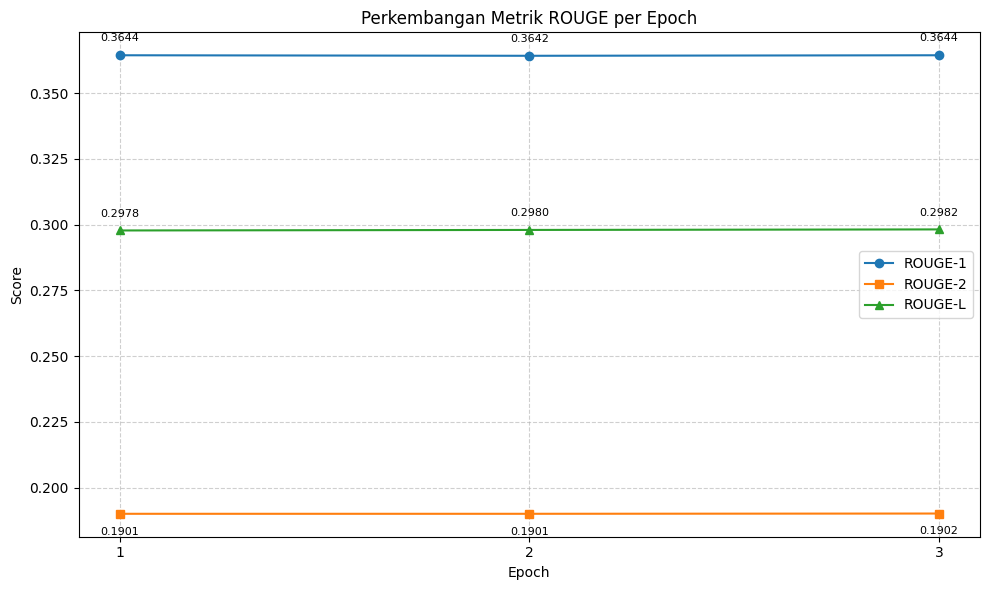

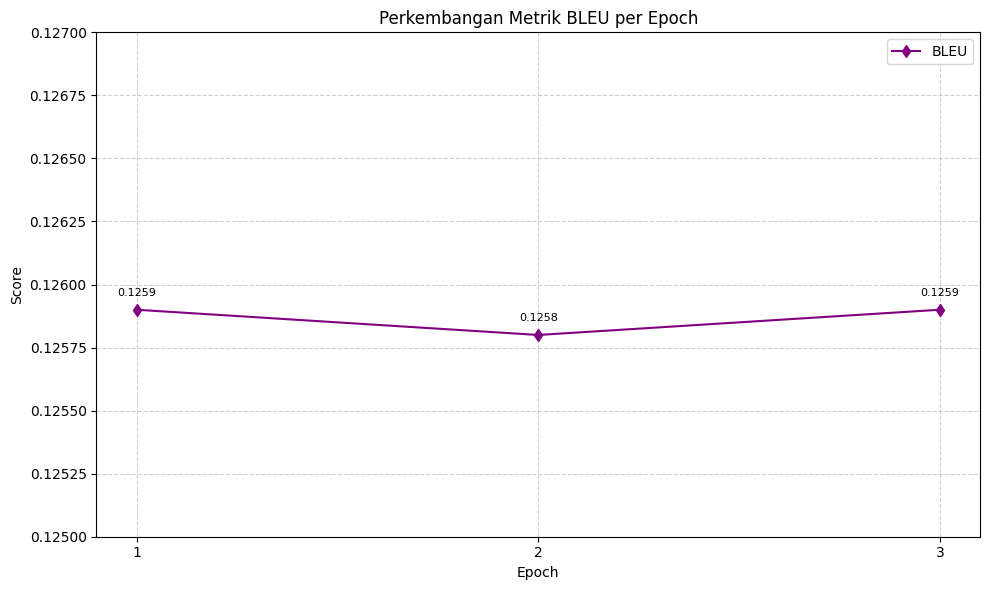

In [ ]:
import matplotlib.pyplot as plt

# data dari log output
epochs = [1, 2, 3]
rouge1_scores = [0.3644, 0.3642, 0.3644]
rouge2_scores = [0.1901, 0.1901, 0.1902]
rougeL_scores = [0.2978, 0.2980, 0.2982]
bleu_scores   = [0.1259, 0.1258, 0.1259]

# Grafik ROUGE
plt.figure(figsize=(10, 6))
plt.plot(epochs, rouge1_scores, label='ROUGE-1', marker='o')
plt.plot(epochs, rouge2_scores, label='ROUGE-2', marker='s')
plt.plot(epochs, rougeL_scores, label='ROUGE-L', marker='^')

plt.title('Perkembangan Metrik ROUGE per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Score')
plt.xticks(epochs)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

for i in range(len(epochs)): # label
    plt.annotate(f'{rouge1_scores[i]:.4f}', (epochs[i], rouge1_scores[i]), textcoords="offset points", xytext=(0, 10), ha='center', fontsize=8)
    plt.annotate(f'{rouge2_scores[i]:.4f}', (epochs[i], rouge2_scores[i]), textcoords="offset points", xytext=(0, -15), ha='center', fontsize=8)
    plt.annotate(f'{rougeL_scores[i]:.4f}', (epochs[i], rougeL_scores[i]), textcoords="offset points", xytext=(0, 10), ha='center', fontsize=8)

plt.tight_layout()
plt.show()

# Grafik BLEU
plt.figure(figsize=(10, 6))
plt.plot(epochs, bleu_scores, label='BLEU', marker='d', color='purple')

plt.title('Perkembangan Metrik BLEU per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Score')
plt.xticks(epochs)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.ylim(0.125, 0.127)

for i in range(len(epochs)): # label
    plt.annotate(f'{bleu_scores[i]:.4f}', (epochs[i], bleu_scores[i]), textcoords="offset points", xytext=(0, 10), ha='center', fontsize=8)

plt.tight_layout()
plt.show()

## 11. Evaluasi Step 1

In [ ]:
# Evaluasi pada test set
eval_s1 = trainer_s1.evaluate(test_l6_tok)
print('Evaluasi Step 1 (Liputan6 Test Set):')
print(f"  ROUGE-1 : {eval_s1['eval_rouge1']:.4f}")
print(f"  ROUGE-2 : {eval_s1['eval_rouge2']:.4f}")
print(f"  ROUGE-L : {eval_s1['eval_rougeL']:.4f}")
print(f"  BLEU    : {eval_s1['eval_bleu']:.4f}")

Training Loss,Validation Loss,Epoch,Rouge1,Rouge2,Rougel,Bleu
No log,nan,0,0.394100,0.218400,0.322400,0.151700


Evaluasi Step 1 (Liputan6 Test Set):
  ROUGE-1 : 0.3941
  ROUGE-2 : 0.2184
  ROUGE-L : 0.3224
  BLEU    : 0.1517


In [ ]:
def generate_summary(text, model, tokenizer, device, num_beams=4):
    """Generate ringkasan dari satu teks artikel."""
    model.eval()
    clean = 'summarize: ' + clean_text(text)  # idT5 dengan prefix
    inputs = tokenizer(
        clean,
        max_length=MAX_INPUT_LENGTH,
        truncation=True,
        return_tensors='pt',
    ).to(device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=MAX_TARGET_LENGTH,
            num_beams=num_beams,
            early_stopping=True,
            no_repeat_ngram_size=3,
            decoder_start_token_id=tokenizer.pad_token_id,
        )

    return tokenizer.decode(outputs[0], skip_special_tokens=True)


model_s1.to(device)

sample_artikel  = val_l6[10][INPUT_COL_L6]
sample_ringkasan = val_l6[10][TARGET_COL_L6]

print('=== Uji Ringkasan Step 1 ===')
print('\n[Artikel] (200 karakter pertama):')
print(sample_artikel[:200], '...')
print('\n[Ringkasan Referensi]:')
print(sample_ringkasan)
print('\n[Ringkasan Model Step 1]:')
print(generate_summary(sample_artikel, model_s1, tokenizer, device))

=== Uji Ringkasan Step 1 ===

[Artikel] (200 karakter pertama):
[['Liputan6', '.', 'com', ',', 'Medan', ':', 'Nyaris', 'saja', 'tiga', 'dari', '10', 'kawanan', 'spesialis', 'pencuri', 'suku', 'cadang', 'alat', 'berat', 'beko', 'dibakar', 'massa', '.'], ['Para', 'tersangka', 'ini', 'tertangkap', 'basah', 'saat', 'beraksi', 'di', 'lokasi', 'penggalian', 'pasir', 'dan', 'batu', 'di', 'Desa', 'Gunung', 'Tinggi', ',', 'Kecamatan', 'Pancur', 'Batu', ',', 'Medan', ',', 'Sumatra', 'Utara', ',', 'Rabu', '(', '13/12', ')', 'siang', '.'], ['Lantaran', 'marah', ',', 'massa', 'juga', 'membakar', 'sebuah', 'mobil', 'yang', 'digunakan', 'kawanan', 'itu', 'untuk', 'mengangkut', 'berbagai', 'hasil', 'curian', '.'], ['Sebelum', 'melaksanakan', 'aksinya', ',', 'kawanan', 'ini', 'terlebih', 'dahulu', 'menyekap', 'tiga', 'orang', 'penjaga', 'beko', '.'], ['Namun', ',', 'seorang', 'di', 'antara', 'korban', 'ini', 'berhasil', 'meloloskan', 'diri', 'dan', 'meminta', 'tolong', 'kepada', 'warga', 'terdekat', '.

## 12. Simpan Model Step 1

In [ ]:
# Simpan LoRA adapter Step 1
model_s1.save_pretrained(STEP1_OUTPUT_DIR)
tokenizer.save_pretrained(STEP1_OUTPUT_DIR)
print(f'LoRA adapter Step 1 tersimpan di: {STEP1_OUTPUT_DIR}')

# Merge dan simpan model penuh Step 1
merged_s1 = model_s1.merge_and_unload()
merged_s1.save_pretrained(STEP1_MERGED_DIR)
tokenizer.save_pretrained(STEP1_MERGED_DIR)
print(f'Merged model Step 1 tersimpan di: {STEP1_MERGED_DIR}')

# Simpan ke Google Drive
from google.colab import drive
drive.mount('/content/drive')

import shutil
for folder in [STEP1_OUTPUT_DIR, STEP1_MERGED_DIR]:
    dest = f'/content/drive/MyDrive/Semester 8/04 Checkpoint 3 - Setelah Sempro/Fine-tuning/idT5/{folder}'
    if os.path.exists(dest):
        shutil.rmtree(dest)
    shutil.copytree(folder, dest)
    print(f'Tersimpan di Google Drive: MyDrive/{folder}')

LoRA adapter Step 1 tersimpan di: ./idt5-lora-step1-liputan6


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Merged model Step 1 tersimpan di: ./idt5-merged-step1-liputan6
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Tersimpan di Google Drive: MyDrive/./idt5-lora-step1-liputan6
Tersimpan di Google Drive: MyDrive/./idt5-merged-step1-liputan6


---
# STEP 2 — Fine-Tuning dengan Dataset BPS DKI Jakarta

## 13. Load & Persiapan Dataset BPS DKI

In [ ]:
import gdown
import pandas as pd

url_rawdata = "https://docs.google.com/spreadsheets/d/17D0qGiVQ6837FH3Hck5PsVwfX0-UuGi5/export?format=xlsx"
gdown.download(url_rawdata, "raw_data.xlsx", quiet=False, fuzzy=True)

df_bps = pd.read_excel('raw_data.xlsx')
print('Shape:', df_bps.shape)
print('Kolom:', df_bps.columns.tolist())
print('\nNull values:')
print(df_bps.isnull().sum())
print('\nContoh data:')
df_bps.head(3)

Downloading...
From: https://docs.google.com/spreadsheets/d/17D0qGiVQ6837FH3Hck5PsVwfX0-UuGi5/export?format=xlsx
To: /content/raw_data.xlsx
2.56MB [00:01, 2.44MB/s]


Shape: (2316, 6)
Kolom: ['Nomor', 'Judul', 'Link', 'Ringkasan', 'Full_Content', 'Indikator']

Null values:
Nomor           0
Judul           0
Link            0
Ringkasan       0
Full_Content    0
Indikator       0
dtype: int64

Contoh data:


,Nomor,Judul,Link,Ringkasan,Full_Content,Indikator
0,1,BPS: Kemiskinan Bisa Ditekan dengan Fokus di Jawa,https://www.republika.co.id/berita/qwj4qa328/b...,BPS melaporkan angka kemiskinan di Indonesia h...,"REPUBLIKA.CO.ID, JAKARTA -- Kepala Badan Pusat...",Lainnya
1,2,Mendes PDTT Minta Ruang Isolasi Desa Diaktifkan,https://microsite.suara.com/kemendesa/read/202...,"Menteri Desa, Pembangunan Daerah Tertinggal, d...",Mendes PDTT Minta Ruang Isolasi Desa Diaktifka...,Lainnya
2,3,"Tambah 1.610 Pasien, Positif Covid-19 di Jakar...",https://jakarta.suara.com/read/2021/08/03/2229...,Jumlah kasus pasien positif terjangkit Covid-1...,SuaraJakarta.id - Jumlah kasus pasien positif ...,Lainnya


In [ ]:
INPUT_COL_BPS  = 'Full_Content'
TARGET_COL_BPS = 'Ringkasan'

df_bps = df_bps[[INPUT_COL_BPS, TARGET_COL_BPS]].dropna().reset_index(drop=True)
print(f'Total data BPS DKI: {len(df_bps)}')

df_bps['panjang_artikel']   = df_bps[INPUT_COL_BPS].str.split().str.len()
df_bps['panjang_ringkasan'] = df_bps[TARGET_COL_BPS].str.split().str.len()
print(f'\nRata-rata panjang artikel   : {df_bps["panjang_artikel"].mean():.0f} kata')
print(f'Rata-rata panjang ringkasan : {df_bps["panjang_ringkasan"].mean():.0f} kata')

Total data BPS DKI: 2316

Rata-rata panjang artikel   : 328 kata
Rata-rata panjang ringkasan : 69 kata


In [ ]:
from sklearn.model_selection import train_test_split

df_train_bps, df_temp_bps = train_test_split(df_bps, test_size=0.2, random_state=42)
df_val_bps, df_test_bps   = train_test_split(df_temp_bps, test_size=0.5, random_state=42)

print(f'Train BPS : {len(df_train_bps)}')
print(f'Val BPS   : {len(df_val_bps)}')
print(f'Test BPS  : {len(df_test_bps)}')

Train BPS : 1852
Val BPS   : 232
Test BPS  : 232


In [ ]:
# Konversi ke HuggingFace Dataset & tokenisasi
def tokenize_bps(examples):
    return tokenize_fn(examples, INPUT_COL_BPS, TARGET_COL_BPS)

train_bps_ds = Dataset.from_pandas(df_train_bps.reset_index(drop=True))
val_bps_ds   = Dataset.from_pandas(df_val_bps.reset_index(drop=True))
test_bps_ds  = Dataset.from_pandas(df_test_bps.reset_index(drop=True))

cols_bps = train_bps_ds.column_names
train_bps_tok = train_bps_ds.map(tokenize_bps, batched=True, remove_columns=cols_bps)
val_bps_tok   = val_bps_ds.map(tokenize_bps, batched=True, remove_columns=cols_bps)
test_bps_tok  = test_bps_ds.map(tokenize_bps, batched=True, remove_columns=cols_bps)

print('Tokenisasi BPS DKI selesai.')

Map:   0%|          | 0/1852 [00:00<?, ? examples/s]

Map:   0%|          | 0/232 [00:00<?, ? examples/s]

Map:   0%|          | 0/232 [00:00<?, ? examples/s]

Tokenisasi BPS DKI selesai.


## 14. Load Model Step 1 & Terapkan LoRA Baru (Step 2)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# load merged model Step 1 sebagai base untuk Step 2
print('Memuat merged model Step 1 sebagai base Step 2...')
base_model_s2 = AutoModelForSeq2SeqLM.from_pretrained(f'/content/drive/MyDrive/Semester 8/04 Checkpoint 3 - Setelah Sempro/Fine-tuning/idT5/{STEP1_MERGED_DIR}')

base_model_s2.config.use_cache = False

# terapkan LoRA baru untuk Step 2
model_s2 = get_peft_model(base_model_s2, lora_config)
model_s2.enable_input_require_grads()
model_s2.print_trainable_parameters()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Memuat merged model Step 1 sebagai base Step 2...


Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


trainable params: 1,769,472 || all params: 246,078,720 || trainable%: 0.7191


## 15. Training Step 2 — BPS DKI

In [ ]:
data_collator_s2 = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model_s2,
    padding=True,
    pad_to_multiple_of=8,
    label_pad_token_id=-100,
)

training_args_s2 = Seq2SeqTrainingArguments(
    output_dir="/content/drive/MyDrive/Semester 8/04 Checkpoint 3 - Setelah Sempro/Fine-tuning/idT5",

    save_strategy="epoch",
    save_steps=1,
    save_total_limit=3,
    logging_strategy="epoch",
    logging_steps=1,
    eval_strategy='epoch',
    eval_steps=1,

    num_train_epochs=10,               # epochs
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    learning_rate=1e-5,               # learning rate

    load_best_model_at_end=True,
    metric_for_best_model='rougeL',
    greater_is_better=True,
    predict_with_generate=True,       # generasi
    generation_max_length=256,
    generation_num_beams=4,

    fp16=False,                          # bit floating point
    seed=42,
    report_to='none',
)

trainer_s2 = Seq2SeqTrainer(
    model=model_s2,
    args=training_args_s2,
    train_dataset=train_bps_tok,
    eval_dataset=val_bps_tok,
    processing_class=tokenizer,
    data_collator=data_collator_s2,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)], # in 3 epoch
)

print('Trainer Step 2 siap. Memulai training...')

Trainer Step 2 siap. Memulai training...


In [ ]:
result_s2 = trainer_s2.train()
print('\nHasil Training Step 2:')
print(result_s2.metrics)

Epoch,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Bleu
1,1.170743,0.811105,0.525100,0.453600,0.487100,0.412400


Epoch,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Bleu
1,1.170743,0.811105,0.525100,0.453600,0.487100,0.412400
2,1.059091,0.800775,0.519400,0.459400,0.488300,0.362700
3,1.015225,0.788068,0.516100,0.458400,0.485500,0.359100
4,0.996036,0.778085,0.519100,0.461500,0.487600,0.361200
5,0.984288,0.772892,0.516700,0.459000,0.484400,0.357400



Hasil Training Step 2:
{'train_runtime': 3206.3696, 'train_samples_per_second': 5.776, 'train_steps_per_second': 0.724, 'total_flos': 6343584764461056.0, 'train_loss': 1.0450766727842133, 'epoch': 5.0}


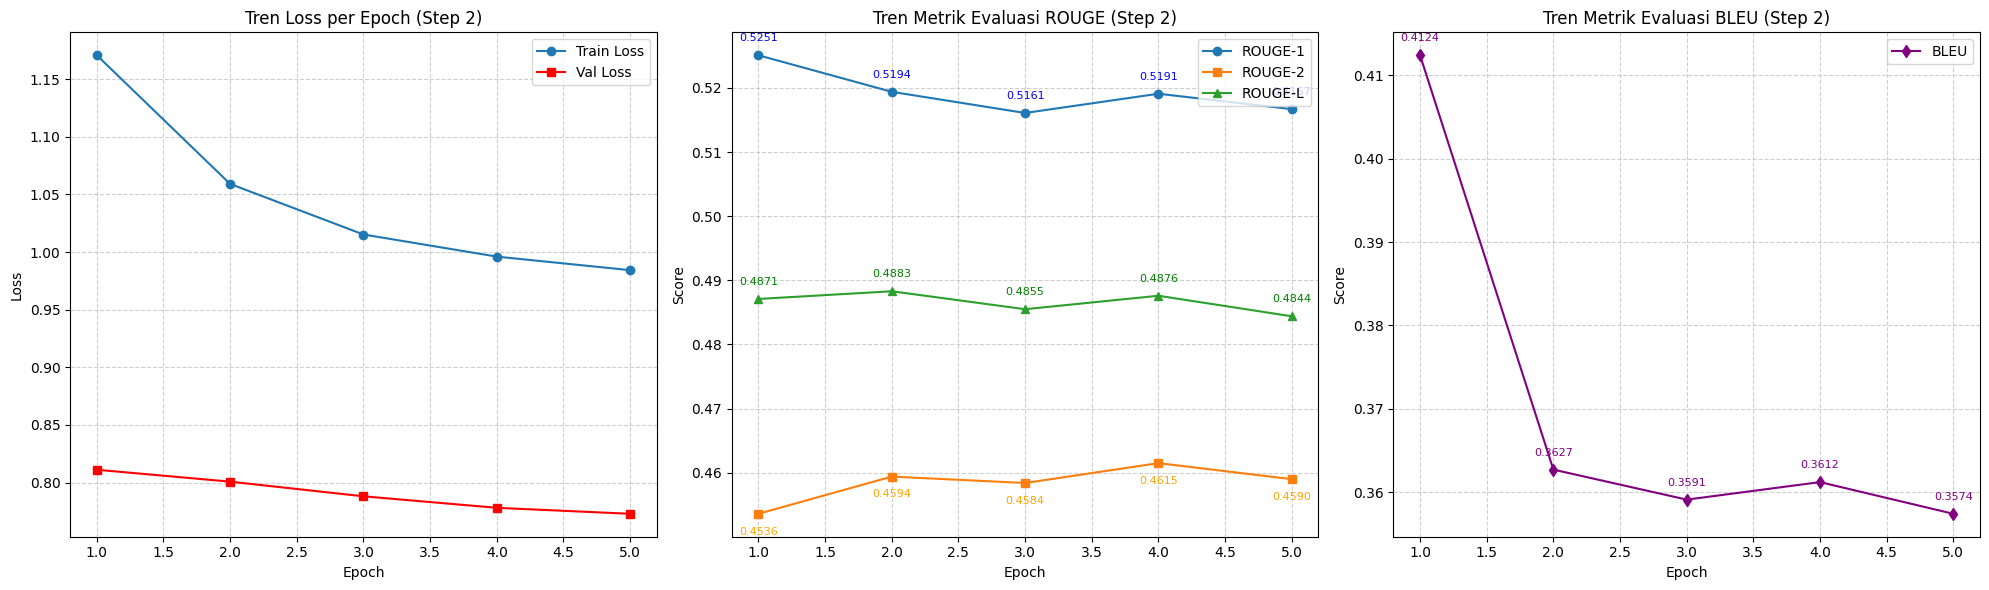

In [ ]:
import matplotlib.pyplot as plt

# Plot training & validation loss for Step 2
log_history = trainer_s2.state.log_history

processed_val_metrics = {}
for x in log_history:
    if 'eval_loss' in x and 'eval_rougeL' in x:
        epoch = x['epoch']
        current_rougeL = x['eval_rougeL']
        current_eval_data = (x['eval_loss'], x['eval_rouge1'], x['eval_rouge2'], x['eval_rougeL'], x['eval_bleu'])

        if epoch not in processed_val_metrics or current_rougeL > processed_val_metrics[epoch][3]:
            processed_val_metrics[epoch] = current_eval_data

# konversi kembali ke list
val_metrics_unique_epochs = sorted([(epoch, *metrics) for epoch, metrics in processed_val_metrics.items()])

epochs_val     = [x[0] for x in val_metrics_unique_epochs]
val_loss       = [x[1] for x in val_metrics_unique_epochs]
val_rouge1     = [x[2] for x in val_metrics_unique_epochs]
val_rouge2     = [x[3] for x in val_metrics_unique_epochs]
val_rougeL     = [x[4] for x in val_metrics_unique_epochs]
val_bleu       = [x[5] for x in val_metrics_unique_epochs]

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

train_loss_unique_epochs = {x['epoch']: x['loss'] for x in log_history if 'loss' in x and 'eval_loss' not in x}
train_epochs_sorted = sorted(train_loss_unique_epochs.keys())
train_losses_sorted = [train_loss_unique_epochs[e] for e in train_epochs_sorted]

# Grafik loss
axes[0].plot(train_epochs_sorted, train_losses_sorted, label='Train Loss', marker='o')
axes[0].plot(epochs_val, val_loss, label='Val Loss', marker='s', color='red')
axes[0].set_title('Tren Loss per Epoch (Step 2)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend()

# Grafik ROUGE
if epochs_val:
    axes[1].plot(epochs_val, val_rouge1, label='ROUGE-1', marker='o')
    axes[1].plot(epochs_val, val_rouge2, label='ROUGE-2', marker='s')
    axes[1].plot(epochs_val, val_rougeL, label='ROUGE-L', marker='^')

    axes[1].set_title('Tren Metrik Evaluasi ROUGE (Step 2)')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Score')
    axes[1].grid(True, linestyle='--', alpha=0.6)
    axes[1].legend()

    def add_labels(ax, x_points, y_points, offset, color='black'): # label
        for i, txt in enumerate(y_points):
            ax.annotate(f"{txt:.4f}", (x_points[i], y_points[i]),
                         textcoords="offset points", xytext=(0, offset), ha='center', fontsize=8, color=color)

    add_labels(axes[1], epochs_val, val_rouge1, 10, color='blue')
    add_labels(axes[1], epochs_val, val_rouge2, -15, color='orange')
    add_labels(axes[1], epochs_val, val_rougeL, 10, color='green')
else:
    axes[1].text(0.5, 0.5, 'No valid ROUGE metric data to plot.', horizontalalignment='center', verticalalignment='center', transform=axes[1].transAxes)

# Grafik BLEU
if epochs_val:
    axes[2].plot(epochs_val, val_bleu, label='BLEU', marker='d', color='purple')

    axes[2].set_title('Tren Metrik Evaluasi BLEU (Step 2)')
    axes[2].set_xlabel('Epoch')
    axes[2].set_ylabel('Score')
    axes[2].grid(True, linestyle='--', alpha=0.6)
    axes[2].legend()

    add_labels(axes[2], epochs_val, val_bleu, 10, color='purple') # label
else:
    axes[2].text(0.5, 0.5, 'No valid BLEU metric data to plot.', horizontalalignment='center', verticalalignment='center', transform=axes[2].transAxes)

plt.tight_layout()
plt.savefig('training_curve_step2.png', dpi=150)
plt.show()

## 16. Evaluasi Step 2 pada Test Set BPS DKI

In [ ]:
# Evaluasi pada test set BPS DKI
eval_s2 = trainer_s2.evaluate(test_bps_tok)
print('Evaluasi Step 2 (BPS DKI Test Set):')
print(f"  ROUGE-1 : {eval_s2['eval_rouge1']:.4f}")
print(f"  ROUGE-2 : {eval_s2['eval_rouge2']:.4f}")
print(f"  ROUGE-L : {eval_s2['eval_rougeL']:.4f}")

Training Loss,Validation Loss,Epoch,Rouge1,Rouge2,Rougel,Bleu
0.984288,0.904660,5,0.497000,0.436400,0.468700,0.347200


Evaluasi Step 2 (BPS DKI Test Set):
  ROUGE-1 : 0.4970
  ROUGE-2 : 0.4364
  ROUGE-L : 0.4687


In [ ]:
# mount drive
from google.colab import drive
drive.mount('/content/drive')

# Load model_s1 dari Drive
STEP1_MERGED_DIR_DRIVE = '/content/drive/MyDrive/Semester 8/04 Checkpoint 3 - Setelah Sempro/Fine-tuning/idT5/idt5-merged-step1-liputan6'
STEP2_MERGED_DIR_DRIVE = '/content/drive/MyDrive/Semester 8/04 Checkpoint 3 - Setelah Sempro/Fine-tuning/idT5/idt5-merged-step2-bps'

print('Memuat model Step 1 dari Drive...')
model_s1 = AutoModelForSeq2SeqLM.from_pretrained(STEP1_MERGED_DIR_DRIVE, local_files_only=True)
model_s1.config.decoder_start_token_id = tokenizer.eos_token_id
model_s1.eval()
print('✓ Model Step 1 berhasil dimuat.')

print('Memuat model Step 2 dari Drive...')
model_s2 = AutoModelForSeq2SeqLM.from_pretrained(STEP2_MERGED_DIR_DRIVE, local_files_only=True)
model_s2.config.decoder_start_token_id = tokenizer.eos_token_id
model_s2.eval()
print('✓ Model Step 2 berhasil dimuat.')

# Perbandingan ROUGE Step 1 vs Step 2 pada BPS DKI test set
model_s1.to(device)
eval_s1_on_bps = trainer_s1.predict(test_bps_tok)

preds_s1  = eval_s1_on_bps.predictions
preds_s1 = np.clip(preds_s1, 0, tokenizer.vocab_size - 1)
preds_s1  = np.where(preds_s1 != -100, preds_s1, tokenizer.pad_token_id)
decoded_s1 = tokenizer.batch_decode(preds_s1, skip_special_tokens=True)

labels_raw = eval_s1_on_bps.label_ids
labels_raw = np.where(labels_raw != -100, labels_raw, tokenizer.pad_token_id)
decoded_ref = tokenizer.batch_decode(labels_raw, skip_special_tokens=True)

rouge_s1_bps = rouge.compute(predictions=decoded_s1, references=decoded_ref)
bleu_s1_bps  = bleu.compute(predictions=decoded_s1, references=[[r] for r in decoded_ref])

model_s2.to(device)
eval_s2_on_bps = trainer_s2.predict(test_bps_tok)

preds_s2 = eval_s2_on_bps.predictions
preds_s2 = np.clip(preds_s2, 0, tokenizer.vocab_size - 1)
preds_s2 = np.where(preds_s2 != -100, preds_s2, tokenizer.pad_token_id)
decoded_s2 = tokenizer.batch_decode(preds_s2, skip_special_tokens=True)

labels_raw = eval_s2_on_bps.label_ids
labels_raw = np.where(labels_raw != -100, labels_raw, tokenizer.pad_token_id)
decoded_ref = tokenizer.batch_decode(labels_raw, skip_special_tokens=True)

rouge_s2_bps = rouge.compute(predictions=decoded_s2, references=decoded_ref)
bleu_s2_bps  = bleu.compute(predictions=decoded_s2, references=[[r] for r in decoded_ref])

print('\n=== Perbandingan ROUGE pada BPS DKI Test Set ===')
print(f"{'Metrik':<12} {'Step 1 (Liputan6)':>20} {'Step 2 (BPS DKI)':>18}")
print('-' * 52)
print(f"{'ROUGE-1':<12} {rouge_s1_bps['rouge1']:>20.4f} {rouge_s2_bps['rouge1']:>18.4f}")
print(f"{'ROUGE-2':<12} {rouge_s1_bps['rouge2']:>20.4f} {rouge_s2_bps['rouge2']:>18.4f}")
print(f"{'ROUGE-L':<12} {rouge_s1_bps['rougeL']:>20.4f} {rouge_s2_bps['rougeL']:>18.4f}")
print(f"{'BLEU':<12} {bleu_s1_bps['bleu']:>20.4f} {bleu_s2_bps['bleu']:>18.4f}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Memuat model Step 1 dari Drive...


Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


✓ Model Step 1 berhasil dimuat.
Memuat model Step 2 dari Drive...


Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


✓ Model Step 1 berhasil dimuat.



=== Perbandingan ROUGE pada BPS DKI Test Set ===
Metrik          Step 1 (Liputan6)   Step 2 (BPS DKI)
----------------------------------------------------
ROUGE-1                    0.0452             0.5139
ROUGE-2                    0.0191             0.4408
ROUGE-L                    0.0433             0.4844
BLEU                       0.0020             0.3525


In [ ]:
def generate_summary(text, model, tokenizer, device, num_beams=4):
    """Generate ringkasan dari satu teks artikel."""
    model.eval()
    clean = 'summarize: ' + clean_text(text)   # idT5 dengan prefix
    inputs = tokenizer(
        clean,
        max_length=MAX_INPUT_LENGTH,
        truncation=True,
        return_tensors='pt',
    ).to(device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=MAX_TARGET_LENGTH,
            num_beams=num_beams,
            early_stopping=True,
            no_repeat_ngram_size=3,
            decoder_start_token_id=tokenizer.pad_token_id,
        )

    return tokenizer.decode(outputs[0], skip_special_tokens=True)

model_s2.to(device)

sample_bps_artikel   = df_test_bps.iloc[10][INPUT_COL_BPS]
sample_bps_ringkasan = df_test_bps.iloc[10][TARGET_COL_BPS]

print('=== Uji Ringkasan Step 2 (Domain BPS DKI) ===')
print('\n[Artikel] (200 karakter pertama):')
print(sample_bps_artikel[:200], '...')
print('\n[Ringkasan Referensi BPS]:')
print(sample_bps_ringkasan)
print('\n[Ringkasan Model Step 1 pada artikel BPS]:')
print(generate_summary(sample_bps_artikel, model_s1, tokenizer, device))
print('\n[Ringkasan Model Step 2 (final)]:')
print(generate_summary(sample_bps_artikel, model_s2, tokenizer, device))

=== Uji Ringkasan Step 2 (Domain BPS DKI) ===

[Artikel] (200 karakter pertama):
Transisi ekonomi Indonesia dari industri ekstraktif ke ekonomi hijau diprediksi dapat memberikan dampak Rp 4.376 triliun ke output ekonomi nasional. Peralihan pun diprediksi memberikan tambahan produk ...

[Ringkasan Referensi BPS]:
Transisi ekonomi Indonesia dari industri ekstraktif ke ekonomi hijau diprediksi dapat memberikan dampak Rp 4.376 triliun ke output ekonomi nasional. Peralihan pun diprediksi memberikan tambahan produk domestik bruto (PDB) sebesar Rp 2.943 triliun dalam 10 tahun mendatang atau setara 14,3% dari total PDB Indonesia pada 2024. Ekonomi hijau juga mampu membuka hingga 19,4 juta lapangan kerja baru yang muncul dari berbagai sektor yang berkaitan dengan pengembangan energi terbarukan (pertanian, kehutanan, perikanan dan jenis-jenis industri ramah lingkungan lainnya) dan pendapatan pekerja secara total dapat bertambah hingga Rp 902,2 triliun.

[Ringkasan Model Step 1 pada artikel BPS]:

## 17. Simpan Model Final (Step 2)

In [ ]:
import shutil

# Simpan LoRA adapter Step 2
model_s2.save_pretrained(STEP2_OUTPUT_DIR)
tokenizer.save_pretrained(STEP2_OUTPUT_DIR)
print(f'LoRA adapter Step 2 tersimpan di: {STEP2_OUTPUT_DIR}')

# Merge dan simpan model penuh Step 2 (model FINAL)
merged_s2 = model_s2.merge_and_unload()
merged_s2.save_pretrained(STEP2_MERGED_DIR)
tokenizer.save_pretrained(STEP2_MERGED_DIR)
print(f'Merged model Step 2 tersimpan di: {STEP2_MERGED_DIR}')

# Simpan ke Google Drive
for folder in [STEP2_OUTPUT_DIR, STEP2_MERGED_DIR]:
    dest = f'/content/drive/MyDrive/Semester 8/04 Checkpoint 3 - Setelah Sempro/Fine-tuning/idT5/{folder}'
    if os.path.exists(dest):
        shutil.rmtree(dest)
    shutil.copytree(folder, dest)
    print(f'Tersimpan di Google Drive: MyDrive/{folder}')

LoRA adapter Step 2 tersimpan di: ./idt5-lora-step2-bps


/usr/local/lib/python3.13/dist-packages/peft/tuners/tuners_utils.py:687: UserWarning: Input and output embeddings are no longer tied after merging. Setting `tie_word_embeddings=False` in the model config.
  warnings.warn(


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Merged model Step 2 tersimpan di: ./idt5-merged-step2-bps
Tersimpan di Google Drive: MyDrive/./idt5-lora-step2-bps
Tersimpan di Google Drive: MyDrive/./idt5-merged-step2-bps


## 18. Load Model Final untuk Inference

In [ ]:
# Load merged model final
# from transformers import AutoModelForSeq2SeqLM, AutoTokenizer
#
# tokenizer_loaded = AutoTokenizer.from_pretrained('./idt5-merged-step2-bps')
# model_loaded = AutoModelForSeq2SeqLM.from_pretrained('./idt5-merged-step2-bps')
# model_loaded.eval()

from google.colab import drive
drive.mount('/content/drive')

STEP1_DIR  = '/content/drive/MyDrive/Semester 8/04 Checkpoint 3 - Setelah Sempro/Fine-tuning/idT5/idt5-merged-step1-liputan6'
STEP2_DIR  = '/content/drive/MyDrive/Semester 8/04 Checkpoint 3 - Setelah Sempro/Fine-tuning/idT5/idt5-merged-step2-bps'

from transformers import AutoModelForSeq2SeqLM, AutoTokenizer
tokenizer_step1_loaded = AutoTokenizer.from_pretrained(STEP1_DIR, local_files_only=True)
model_step1_loaded = AutoModelForSeq2SeqLM.from_pretrained(
    STEP1_DIR, local_files_only=True
)
model_step1_loaded.to(device)
model_step1_loaded.eval()
print(f'Model step 1 berhasil dimuat dan dipindah ke: {device}')

tokenizer_step2_loaded = AutoTokenizer.from_pretrained(STEP2_DIR, local_files_only=True)
model_step2_loaded = AutoModelForSeq2SeqLM.from_pretrained(
    STEP2_DIR, local_files_only=True
)
model_step2_loaded.to(device)
model_step2_loaded.eval()
print(f'Model step 2 berhasil dimuat dan dipindah ke: {device}')

# Load LoRA Adapter
# from peft import PeftModel
# from transformers import AutoModelForSeq2SeqLM, AutoTokenizer
#
# tokenizer_loaded = AutoTokenizer.from_pretrained('./idt5-lora-step2-bps')
# base = AutoModelForSeq2SeqLM.from_pretrained('./idt5-merged-step1-liputan6')
# model_loaded = PeftModel.from_pretrained(base, './idt5-lora-step2-bps')
# model_loaded.eval()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Model step 1 berhasil dimuat dan dipindah ke: cuda


Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Model step 2 berhasil dimuat dan dipindah ke: cuda


In [ ]:
berita = """Gubernur DKI Jakarta, Pramono Anung, menyatakan bahwa partisipasi masyarakat dalam Pendataan Lapangan Sensus Ekonomi 2026 (SE2026) yang dilakukan Badan Pusat Statistik (BPS) penting untuk menghasilkan data ekonomi Jakarta yang akurat, sebagai dasar pemerintah dalam menyusun kebijakan.
Gubernur sendiri menerima menerima petugas BPS DKI Jakarta yang melakukan pendataan Sensus Ekonomi 2026, baru-baru ini.
"Petugas BPS yang datang hari ini secara langsung menanyakan sesuai dengan tugas dalam melakukan sensus. Saya menjawab secara apa adanya, sesuai kondisi sebenarnya," kata Pramono.
Ia kemudian mendorong masyarakat yang belum terdata maupun yang masih ragu memberikan informasi agar terbuka kepada petugas BPS. Menurutnya, data yang akurat membantu pemerintah memahami kondisi perekonomian Jakarta secara lebih utuh.
"Saya mengimbau kepada masyarakat di Jakarta untuk membantu BPS dalam melakukan tugas mereka, yaitu sensus ekonomi. Saya mengimbau seluruh masyarakat Jakarta untuk memberikan data apa adanya. Jangan tertutup," ujarnya.
Pramono menegaskan, informasi yang diberikan dalam Sensus Ekonomi 2026 bersifat rahasia. Pendataan dipastikan tidak berkaitan dengan perpajakan ataupun kepentingan lain di luar kebutuhan statistik.
"Ini betul-betul adalah sensus ekonomi untuk mengetahui potret kondisi dan keadaan di Jakarta. Masyarakat diminta memberikan jawaban apa adanya, sesuai dengan kondisi yang sebenarnya, karena data ini akan menjadi referensi dalam mengambil keputusan," tutur Pramono.
Sebagai salah satu pusat kegiatan ekonomi terbesar di Indonesia, keberagaman kegiatan usaha yang tumbuh di Jakarta, mulai dari usaha rumahan, UMKM, hingga perusahaan berskala besar dan internasional, perlu tercatat agar gambaran perekonomian Jakarta tidak hanya mencerminkan kegiatan usaha yang terlihat secara kasatmata.
Selama pendataan, petugas BPS mendatangi berbagai lokasi usaha, seperti mal, kawasan bisnis, pasar, pertokoan, pusat perbelanjaan, rumah, dan apartemen untuk bertemu langsung dengan pelaku usaha dan masyarakat.
Sementara, sebagian responden mengikuti pendataan melalui pengisian kuesioner secara mandiri.
Sensus Ekonomi ini bukan hanya menghitung jumlah usaha. Data yang dikumpulkan mencakup jenis kegiatan usaha, produk dan jasa yang dihasilkan, skala usaha, tenaga kerja, pemanfaatan teknologi, serta berbagai karakteristik lainnya.
Data itu diharapkan memberikan gambaran yang lebih lengkap mengenai perkembangan ekonomi Jakarta, termasuk usaha yang selama ini belum tercatat dalam data administrasi pemerintah.
Untuk diketahui, hasil SE2026 akan menjadi salah satu rujukan Pemerintah Provinsi (Pemprov) DKI Jakarta dalam menyusun program, kebijakan, regulasi, dan intervensi yang lebih tepat sasaran berdasarkan kondisi ekonomi terkini.
"Data yang benar akan membantu pemerintah mengambil keputusan yang benar. Karena itu saya mengajak masyarakat untuk ikut menyukseskan sensus ekonomi," ujar Gubernur.
Dalam kesempatan yang sama, ia juga meminta Dinas Pendidikan DKI Jakarta melakukan pengecekan ulang terhadap mahasiswa penerima Kartu Jakarta Mahasiswa Unggul (KJMU) yang terdampak perubahan data desil.
Langkah ini bertujuan memastikan mahasiswa yang sebelumnya menerima KJMU tidak kehilangan akses pendidikan akibat perubahan data yang masih perlu diverifikasi.
Sementara itu, Sekretaris Utama BPS RI, Zulkipli, mengatakan pelaksanaan pendataan Sensus Ekonomi 2026 di Jakarta berjalan lancar.
Berdasarkan pre-list yang tersedia, BPS telah melakukan pendataan sebesar 111 persen. Hingga kini, masih terdapat sejumlah unit usaha yang belum ditemukan atau dokumennya masih dalam proses penelusuran.
"Waktu kita masih ada sampai dengan 15 September. Kami akan mendatangi kembali perusahaan-perusahaan itu serta menemukan kembali yang tadinya belum ditemukan dalam pre-list kami," kata Zulikpli.
Zulkipli juga mengajak masyarakat dan pelaku usaha yang belum terdata untuk menghubungi Kantor BPS. Pendataan masih akan berlangsung hingga pertengahan September 2026.
"Untuk masyarakat di DKI Jakarta dapat membantu BPS dalam pelaksanaan Sensus Ekonomi 2026. Bagi yang belum terdata, nanti kita bisa lakukan pendataan atau bisa menghubungi kantor BPS. Waktu kita masih ada hingga pertengahan September 2026," pungkas Zulkipli.
https://www.cnnindonesia.com/nasional/20260901114547-25-1398660/gubernur-dki-ikuti-sensus-ekonomi-dorong-warga-terbuka-pada-petugas"""


import time
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

def generate_summary(text, model, tokenizer, device, num_beams=4):
    """Generate ringkasan dari satu teks artikel."""
    model.eval()
    clean = 'summarize: ' + clean_text(text)  # idT5 dengan prefix
    inputs = tokenizer(
        clean,
        max_length=MAX_INPUT_LENGTH,
        truncation=True,
        return_tensors='pt',
    ).to(device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=MAX_TARGET_LENGTH,
            num_beams=num_beams,
            early_stopping=True,
            no_repeat_ngram_size=3,
        )

    return tokenizer.decode(outputs[0], skip_special_tokens=True)

def timed_summary(text, model, tokenizer, device):
    """Menghitung runtime inferensi (dalam detik) untuk meringkas satu teks (single run)."""
    if device.type == 'cuda':
        torch.cuda.synchronize()  # cek GPU tidak beroperasi

    start = time.perf_counter()
    summary = generate_summary(text, model, tokenizer, device)
    if device.type == 'cuda':
        torch.cuda.synchronize()  # tunggu GPU selesai sebelum stop timer
    end = time.perf_counter()
    duration_s = (end - start)

    return summary, duration_s

print('\n=== Uji Ringkasan dan Waktu Inferensi ===')

# Inference for Model Step 1
print('\n--- Model Step 1 (Fine-tuned on Liputan6) ---')
summary_s1, duration_s1 = timed_summary(berita, model_step1_loaded, tokenizer_step1_loaded, device)
print(f'[Ringkasan Model Step 1]:\n{summary_s1}')
print(f'Waktu Eksekusi : {duration_s1:.3f} s')

# Inference for Model Step 2
print('\n--- Model Step 2 (Fine-tuned on BPS DKI) ---')
summary_s2, duration_s2 = timed_summary(berita, model_step2_loaded, tokenizer_step2_loaded, device)
print(f'[Ringkasan Model Step 2]:\n{summary_s2}')
print(f'Waktu Eksekusi : {duration_s2:.3f} s')


=== Uji Ringkasan dan Waktu Inferensi ===

--- Model Step 1 (Fine-tuned on Liputan6) ---


[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[Ringkasan Model Step 1]:
gubernur dki jakarta, pramono anung, menyatakan bahwa partisipasi masyarakat dalam pendataan lapangan sensus ekonomi 2026 penting untuk menghasilkan data ekonomi jakarta yang akurat, sebagai dasar pemerintah dalam menyusun kebijakan.
Waktu Eksekusi : 5.089 s

--- Model Step 2 (Fine-tuned on BPS DKI) ---
[Ringkasan Model Step 2]:
gubernur dki jakarta, pramono anung, menyatakan bahwa partisipasi masyarakat dalam pendataan lapangan sensus ekonomi 2026 (se2026) yang dilakukan badan pusat statistik (bps) penting untuk menghasilkan data ekonomi jakarta yang akurat, sebagai dasar pemerintah dalam menyusun kebijakan.
Waktu Eksekusi : 7.761 s


In [ ]:
# Inferensi data Human Evaluation
from google.colab import drive
drive.mount('/content/drive')

STEP1_DIR  = '/content/drive/MyDrive/Semester 8/04 Checkpoint 3 - Setelah Sempro/Fine-tuning/idT5/idt5-merged-step1-liputan6'
STEP2_DIR  = '/content/drive/MyDrive/Semester 8/04 Checkpoint 3 - Setelah Sempro/Fine-tuning/idT5/idt5-merged-step2-bps'

from transformers import AutoModelForSeq2SeqLM, AutoTokenizer
tokenizer_step1_loaded = AutoTokenizer.from_pretrained(STEP1_DIR, local_files_only=True)
model_step1_loaded = AutoModelForSeq2SeqLM.from_pretrained(
    STEP1_DIR, local_files_only=True
)
model_step1_loaded.to(device)
model_step1_loaded.eval()
print(f'Model step 1 berhasil dimuat dan dipindah ke: {device}')

tokenizer_step2_loaded = AutoTokenizer.from_pretrained(STEP2_DIR, local_files_only=True)
model_step2_loaded = AutoModelForSeq2SeqLM.from_pretrained(
    STEP2_DIR, local_files_only=True
)
model_step2_loaded.to(device)
model_step2_loaded.eval()
print(f'Model step 2 berhasil dimuat dan dipindah ke: {device}')

import gdown
import pandas as pd

url_rawdata = "https://docs.google.com/spreadsheets/d/1XO_x49SQmtz9gmHpo87I4K8U4lr7YOq3/export?format=xlsx"
gdown.download(url_rawdata, "humaneval_data.xlsx", quiet=False, fuzzy=True)

df_he = pd.read_excel('humaneval_data.xlsx')
print('Shape:', df_he.shape)
print('Kolom:', df_he.columns.tolist())
print('\nNull values:')
print(df_he.isnull().sum())
print('\nContoh data:')
df_he.head(3)

import time
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

def generate_summary(text, model, tokenizer, device, num_beams=4):
    """Generate ringkasan dari satu teks artikel."""
    model.eval()
    clean = "summarize: " + clean_text(text)  # idT5 dengan prefix
    inputs = tokenizer(
        clean,
        max_length=MAX_INPUT_LENGTH,
        truncation=True,
        return_tensors='pt',
    ).to(device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=MAX_TARGET_LENGTH,
            num_beams=num_beams,
            early_stopping=True,
            no_repeat_ngram_size=3,
        )

    return tokenizer.decode(outputs[0], skip_special_tokens=True)

def timed_summary(text, model, tokenizer, device):
    """Menghitung runtime inferensi (dalam detik) untuk meringkas satu teks (single run)."""
    if device.type == 'cuda':
        torch.cuda.synchronize()  # cek GPU tidak beroperasi

    start = time.perf_counter()
    summary = generate_summary(text, model, tokenizer, device)
    if device.type == 'cuda':
        torch.cuda.synchronize()  # tunggu GPU selesai sebelum stop timer
    end = time.perf_counter()
    duration_s = (end - start)

    return summary, duration_s

import numpy as np
TEXT_COLUMN = 'Full_Content'

texts_he = df_he[TEXT_COLUMN].tolist()

# Warm-up
for text in texts_he:
    _ = timed_summary(text, model_step1_loaded, tokenizer_step1_loaded, device)
    _ = timed_summary(text, model_step2_loaded, tokenizer_step2_loaded, device)

durasi_step1_s   = []
ringkasan_step1  = []
durasi_step2_s   = []
ringkasan_step2  = []

print('=== Generate Step 1 ===')
for i, text in enumerate(texts_he):
    summary, duration = timed_summary(text, model_step1_loaded, tokenizer_step1_loaded, device)
    durasi_step1_s.append(duration)
    ringkasan_step1.append(summary)
    print(f"[{i+1}/{len(texts_he)}] {duration:.2f} s  -> {summary[:60]}...")

print('\n=== Generate Step 2 ===')
for i, text in enumerate(texts_he):
    summary, duration = timed_summary(text, model_step2_loaded, tokenizer_step2_loaded, device)
    durasi_step2_s.append(duration)
    ringkasan_step2.append(summary)
    print(f"[{i+1}/{len(texts_he)}] {duration:.2f} s  -> {summary[:60]}...")

durasi_step1_s = np.array(durasi_step1_s)
durasi_step2_s = np.array(durasi_step2_s)

def print_stats(nama, durasi):
    print(f"\n=== Runtime Inferensi {nama} ({len(texts_he)} berita, {device}) ===")
    print(f"Rata-rata : {durasi.mean():.2f} s")
    print(f"Std. dev  : {durasi.std():.2f} s")
    print(f"Median    : {np.median(durasi):.2f} s")
    print(f"Min / Max : {durasi.min():.2f} s / {durasi.max():.2f} s")
    print(f"Total     : {durasi.sum():.2f} s")

print_stats('idT5 Step 1', durasi_step1_s)
print_stats('idT5 Step 2', durasi_step2_s)

# Simpan hasil generate + waktu ke kolom baru
df_he['Ringkasan_idT5_Step1'] = ringkasan_step1
df_he['Runtime_idT5_Step1_s'] = durasi_step1_s
df_he['Ringkasan_idT5_Step2'] = ringkasan_step2
df_he['Runtime_idT5_Step2_s'] = durasi_step2_s

output_path = 'humaneval_hasil_idT5.xlsx'
df_he.to_excel(output_path, index=False)
print(f"\nHasil disimpan ke: {output_path}")

# Salin juga ke Google Drive
# import shutil
# drive_dest = '/content/drive/MyDrive/Semester 8/04 Checkpoint 3 - Setelah Sempro/Fine-tuning/idT5/humaneval_hasil_idT5.xlsx'
# shutil.copy(output_path, drive_dest)
# print(f"Disalin ke Drive: {drive_dest}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Model step 1 berhasil dimuat dan dipindah ke: cuda


Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

...

[27/30] 3.69 s  -> taman ismail marzuki (tim) adalah salah satu spot wisata yan...


[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[28/30] 2.32 s  -> kepala disnakertransgi dki jakarta, hari nugroho, mengatakan...


[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[29/30] 2.93 s  -> massa dari berbagai elemen, salah satunya bem si, menggelar ...
[30/30] 2.58 s  -> pemprov dki sedang melakukan uji coba program makan bergizi ...

=== Runtime Inferensi idT5 Step 1 (30 berita, cuda) ===
Rata-rata : 1.47 s
Std. dev  : 0.33 s
Median    : 1.41 s
Min / Max : 0.98 s / 2.73 s
Total     : 44.22 s

=== Runtime Inferensi idT5 Step 2 (30 berita, cuda) ===
Rata-rata : 2.77 s
Std. dev  : 0.52 s
Median    : 2.92 s
Min / Max : 1.59 s / 3.69 s
Total     : 83.13 s

Hasil disimpan ke: humaneval_hasil_idT5.xlsx


In [ ]:
# Inferensi MDS
import numpy as np
import time

num_articles = len(df_he)
if num_articles % 3 != 0:
    print("Jumlah berita tidak kelipatan 3.")

num_sets = num_articles // 3

mds_summaries = []
mds_runtimes = []

print(f'MDS untuk {num_sets} set berita')

for i in range(0, num_articles, 3):
    # ambil set berita
    current_set_articles = df_he.iloc[i : i + 3]

    if len(current_set_articles) < 3:
        continue

    # menyatukan ringkasan SDS
    sds_summaries_combined = " ".join(current_set_articles['Ringkasan_idT5_Step2'].tolist())

    # MDS dengan final model
    mds_summary, duration = timed_summary(
        sds_summaries_combined,
        model_step2_loaded,
        tokenizer_step2_loaded,
        device
    )

    mds_summaries.append(mds_summary)
    mds_runtimes.append(duration)

    print(f"Set {i//3 + 1}/{num_sets}: {duration:.3f} s -> {mds_summary[:80]}...")


mds_runtimes_np = np.array(mds_runtimes)
print(f"\n=== Runtime Inferensi MDS ({num_sets} set) ===")
print(f"Rata-rata : {mds_runtimes_np.mean():.3f} s per set")
print(f"Std. dev  : {mds_runtimes_np.std():.3f} s")
print(f"Median    : {np.median(mds_runtimes_np):.3f} s")
print(f"Min / Max : {mds_runtimes_np.min():.3f} s / {mds_runtimes_np.max():.3f} s")
print(f"Total     : {mds_runtimes_np.sum():.3f} s")

# Add hasil MDS
df_he['Ringkasan_MDS_idT5'] = ''
df_he['Runtime_MDS_idT5_s'] = np.nan

for j in range(len(mds_summaries)):
    start_idx = j * 3
    if start_idx < len(df_he):
        df_he.at[start_idx, 'Ringkasan_MDS_idT5'] = mds_summaries[j]
        df_he.at[start_idx, 'Runtime_MDS_idT5_s'] = mds_runtimes[j]

# Save
output_path_mds = 'humaneval_hasil_idt5_mds.xlsx'
df_he.to_excel(output_path_mds, index=False)

[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


MDS untuk 10 set berita


[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Set 1/10: 3.344 s -> federasi organisasi ekspor india (federation of indian export organisations - fi...


[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

Set 7/10: 3.783 s -> kepala perwakilan bank indonesia provinsi dki jakarta arlyana abubakar mengataka...


[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Set 8/10: 2.515 s -> pada agustus 2023, angka inflasi dki adalah 2,93% berada dalam bawah inflasi nas...


[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Set 9/10: 2.432 s -> pemprov dki jakarta melalui dinkes memprediksi, pandemi covid-19 paling cepat be...
Set 10/10: 3.126 s -> kepala disnakertransgi dki jakarta, hari nugroho, mengatakan berdasar hasil peme...

=== Runtime Inferensi MDS (10 set) ===
Rata-rata : 3.341 s per set
Std. dev  : 0.502 s
Median    : 3.358 s
Min / Max : 2.432 s / 3.976 s
Total     : 33.409 s
